In [174]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [175]:
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines, plot_line_diff
from crafts_stack.halo_fitting import gen_test_data, build_model, halofit, cov_to_err_map

# gaussian

In [176]:
name = 'gaussian'

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

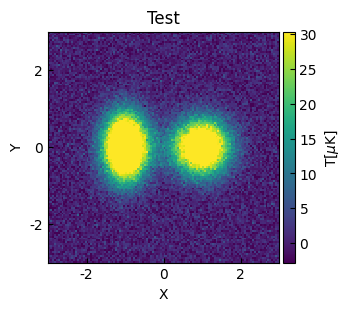

In [177]:
coord = get_coord()
param_h1 = {
    "amplitude": 60,
    "x_mean": -1,
    "y_mean": 0,
    "x_stddev": 0.4,
    "y_stddev": 0.6,
}
nstd = 2
data = gen_test_data('gaussian',None, *coord, param_h1=param_h1, noise_std=nstd)
data[50:70, 50:70] += 2
plot_heatmap(data, title='Test')

In [178]:
model = build_model('gaussian', 'const')
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [1]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 x_stddev_0 ... y_stddev_1 theta_1 amplitude_2
    ----------- -------- -------- ---------- ... ---------- ------- -----------
           50.0     -1.0      0.0        0.5 ...        0.5     0.0         0.0


# without mask

In [179]:
data_list, fit_model, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=59.9060443, x_mean=-0.99514573, y_mean=0.00111033, x_stddev=0.40562139, y_stddev=0.59787945, theta=-15.70042139)>

    [1]: <Gaussian2D(amplitude=49.98651411, x_mean=0.98590289, y_mean=0.0023548, x_stddev=0.51102434, y_stddev=0.49732225, theta=0.03178309)>

    [2]: <Const2D(amplitude=0.0006998)>
Parameters:
       amplitude_0           x_mean_0      ...      amplitude_2     
    ------------------ ------------------- ... ---------------------
    59.906044296485824 -0.9951457268287057 ... 0.0006997980341511167

Goodness of fit:
Chi-squared: 58543.104
Reduced chi-squared: 4.069
RMS residual: 2.016



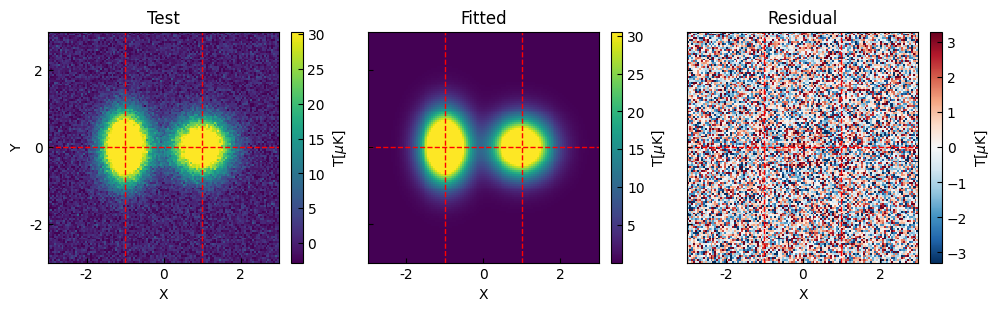

In [180]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

[<Axes: title={'center': 'X=0'}>, <Axes: >]

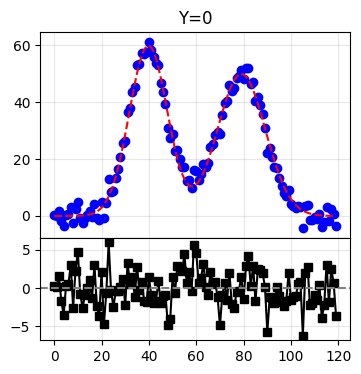

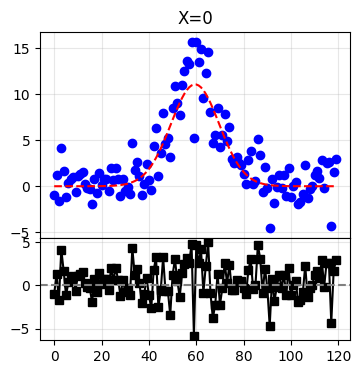

In [181]:
plot_line_diff(data_list[0][60], data_list[1][60], title='Y=0')
plot_line_diff(data_list[0][:, 60], data_list[1][:, 60], title='X=0')

<Axes: title={'center': 'Error'}, xlabel='X', ylabel='Y'>

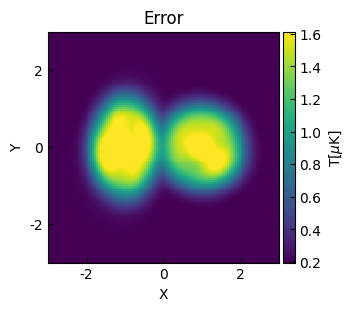

In [182]:
error = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error, title='Error')

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

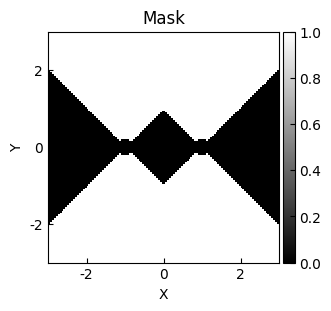

In [183]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [184]:
data_list_sector, fit_model, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=60.30114205, x_mean=-1.00041076, y_mean=0.00104244, x_stddev=0.39755464, y_stddev=0.59805289, theta=0.00603766)>

    [1]: <Gaussian2D(amplitude=50.25998127, x_mean=1.00302877, y_mean=0.0011264, x_stddev=0.49948051, y_stddev=0.49698963, theta=0.5097284)>

    [2]: <Const2D(amplitude=0.03858676)>
Parameters:
       amplitude_0          x_mean_0      ...      theta_1           amplitude_2    
    ----------------- ------------------- ... ------------------ -------------------
    60.30114204627842 -1.0004107632042316 ... 0.5097283971109836 0.03858675937933926

Goodness of fit:
Chi-squared: 40714.390
Reduced chi-squared: 3.955
RMS residual: 1.987



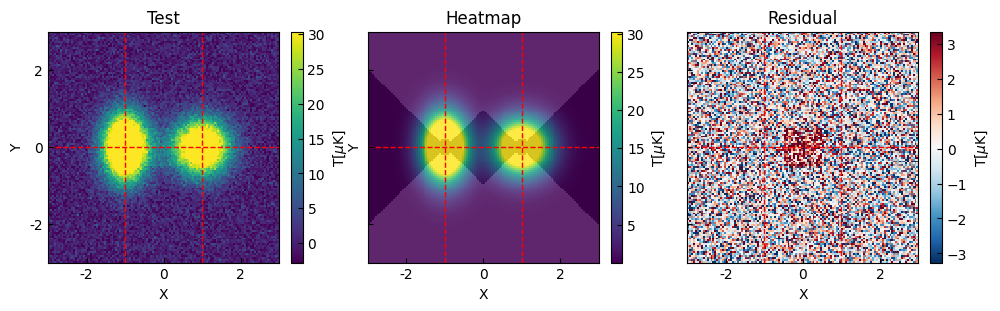

In [185]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

[<Axes: title={'center': 'X=0'}>, <Axes: >]

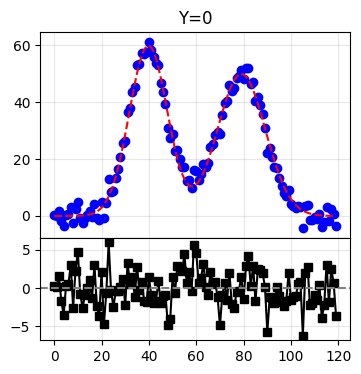

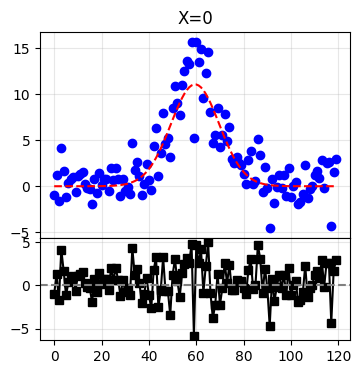

In [186]:
plot_line_diff(data_list[0][60], data_list[1][60], title='Y=0')
plot_line_diff(data_list[0][:, 60], data_list[1][:, 60], title='X=0')

<Axes: title={'center': 'Error'}, xlabel='X', ylabel='Y'>

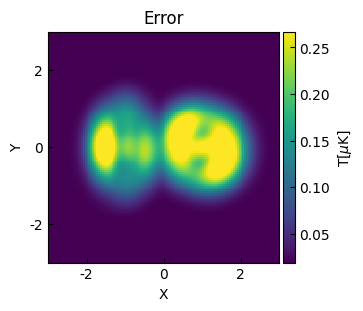

In [187]:
error = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error, title='Error')

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

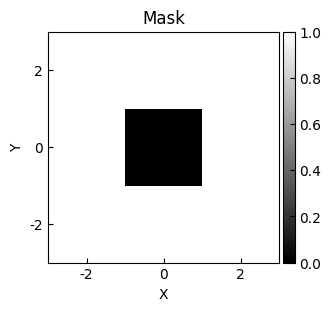

In [188]:
mask = ~get_mask_square(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [189]:
data_list_square, fit_model, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Gaussian2D(amplitude=59.99062182, x_mean=-1.00379857, y_mean=0.00282115, x_stddev=0.39605672, y_stddev=0.59965559, theta=69.11905876)>

    [1]: <Gaussian2D(amplitude=49.91392631, x_mean=1.01058284, y_mean=0.0039471, x_stddev=0.48802367, y_stddev=0.49921725, theta=-0.00696731)>

    [2]: <Const2D(amplitude=0.02376464)>
Parameters:
       amplitude_0           x_mean_0      ...     amplitude_2     
    ------------------ ------------------- ... --------------------
    59.990621816985495 -1.0037985682041013 ... 0.023764637824229367

Goodness of fit:
Chi-squared: 50983.579
Reduced chi-squared: 3.987
RMS residual: 1.996



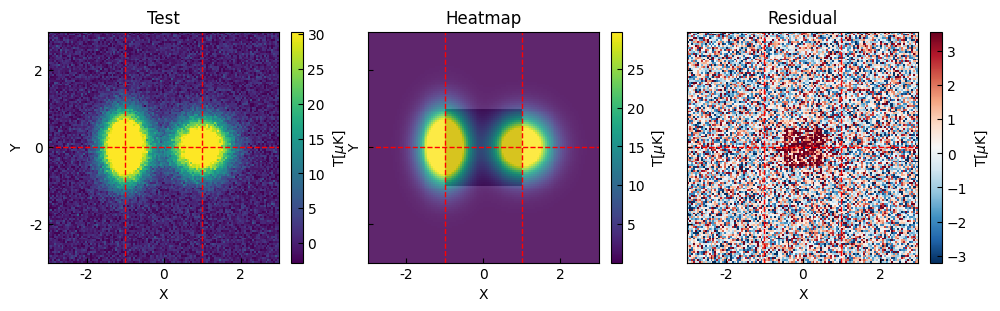

In [190]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

[<Axes: title={'center': 'X=0'}>, <Axes: >]

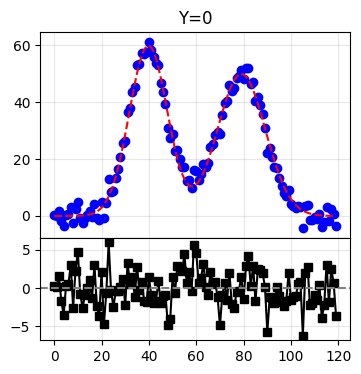

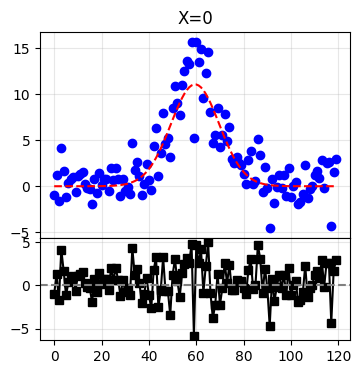

In [191]:
plot_line_diff(data_list[0][60], data_list[1][60], title='Y=0')
plot_line_diff(data_list[0][:, 60], data_list[1][:, 60], title='X=0')

<Axes: title={'center': 'Error'}, xlabel='X', ylabel='Y'>

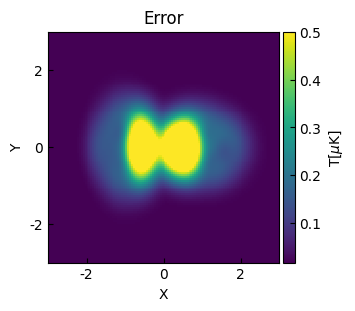

In [192]:
error = cov_to_err_map(fit_model, fit_info, *coord)
plot_heatmap(error, title='Error')

# compare

In [193]:
from mytools.plot import plot_hist

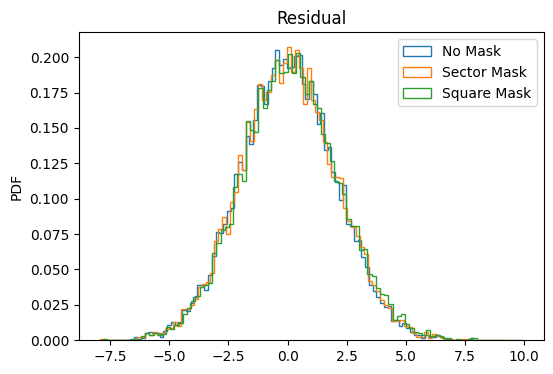

In [194]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
title = ['No Mask', 'Sector Mask', 'Square Mask']
ax = plot_hist(res_list, label=title, bins=100, title='Residual')